<a href="https://colab.research.google.com/github/OleksandrKolesnichenko/cafe_sales_DTA26/blob/main/notebooks/eda_cafe_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ☕ Робочий зошит: очищення даних та EDA
## Датасет: продажі кафе («брудні» дані)

У цьому зошиті ви пройдете повний шлях аналітика: від «брудного» файлу з помилками до чистої таблиці, графіків і висновків для власника кафе.

**Як працювати:**
- Запускайте клітинки **по черзі**, зверху вниз.
- Пишіть код у клітинках з коментарем `# Ваш код тут`.
- У кожному завданні є три частини: **що зробити**, **навіщо** це потрібно і **команди**, які знадобляться.
- Висновки записуйте в клітинки з позначкою ✏️. Пишіть їх своїми словами і з конкретними числами.
- Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Зазирайте туди, лише якщо справді застрягли. Якщо щось зламалося, можна запустити її: вона заново виконає всі кроки й створить усі змінні.

**Структура:**
- **Частина 1.** Первинний огляд: що не так з даними.
- **Частина 2.** Очищення: виправляємо типи, відновлюємо пропуски, додаємо нові стовпці.
- **Частина 3.** EDA: товари, оплата, час, викиди, зв'язки між числами.
- **Частина 4.** Підсумковий звіт і рекомендації.

## Про дані

Датасет **Cafe Sales — Dirty Data for Cleaning Training** (Kaggle) містить 10 000 продажів кафе за 2023 рік. Дані синтетичні й навмисно «зіпсовані»: у них є пропуски, слова `ERROR` і `UNKNOWN` замість значень та інші проблеми.

| Стовпець | Що містить |
|---|---|
| `Transaction ID` | унікальний номер продажу |
| `Item` | товар: кава, чай, торт тощо |
| `Quantity` | кількість одиниць товару |
| `Price Per Unit` | ціна однієї одиниці, $ |
| `Total Spent` | сума продажу, $ (= кількість × ціна) |
| `Payment Method` | спосіб оплати |
| `Location` | де купили: у закладі чи на виніс |
| `Transaction Date` | дата продажу |

## ⚙️ Підготовка
Запустіть клітинку нижче. Вона підключає бібліотеки, задає шлях до файлу з даними і стиль графіків.

💡 Якщо посилання на файл не відкривається, завантажте `dirty_cafe_sales.csv` у панель 📁 ліворуч і замініть значення `FILE_IN` на `"dirty_cafe_sales.csv"`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Звідки читаємо «брудні» дані і куди збережемо чисті
FILE_IN = "https://raw.githubusercontent.com/OleksandrKolesnichenko/cafe_sales_DTA26/refs/heads/main/data/dirty_cafe_sales.csv"
FILE_OUT = "cafe_sales_clean.csv"

# Єдиний стиль для всіх графіків
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

print("Ready!")


Ready!


---
# Частина 1. Первинний огляд

Перш ніж щось виправляти, треба зрозуміти, **що саме** не так з даними. У цій частині ми нічого не змінюємо по суті, лише дивимося й рахуємо.

## Завдання 1.1. Завантаження і перший погляд

**Що зробити:**
1. Прочитайте файл `FILE_IN` у змінну `df_original`.
2. Зробіть копію в змінну `df`. Далі працюйте лише з `df`.
3. Виведіть розмір таблиці (рядки і стовпці), перші 10 рядків і `info()`.

**Навіщо:** `df_original` лишається незмінним «зліпком» вихідних даних. Наприкінці ми порівняємо з ним результат і порахуємо, скільки рядків втратили під час очищення. А якщо щось піде не так, завжди можна почати з чистого аркуша.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `pd.read_csv(FILE_IN)` | прочитати CSV-файл у таблицю |
| `df.copy()` | незалежна копія таблиці |
| `df.shape` | (кількість рядків, кількість стовпців) |
| `df.head(10)` | перші 10 рядків |
| `df.info()` | типи стовпців і кількість заповнених значень |

In [2]:
df_original = pd.read_csv(FILE_IN)
df = df_original.copy()
df.info()
print("Размер таблицы (строки, столбцы):")
print(df.shape)
print("\nПервые 10 строк:")
display(df.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB
Размер таблицы (строки, столбцы):
(10000, 8)

Первые 10 строк:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
5,TXN_2602893,Smoothie,5,4.0,20.0,Credit Card,NaN,2023-03-31
6,TXN_4433211,UNKNOWN,3,3.0,9.0,ERROR,Takeaway,2023-10-06
7,TXN_6699534,Sandwich,4,4.0,16.0,Cash,UNKNOWN,2023-10-28
8,TXN_4717867,NaN,5,3.0,15.0,NaN,Takeaway,2023-07-28
9,TXN_2064365,Sandwich,5,4.0,20.0,NaN,In-store,2023-12-31


✏️ **Спостереження:** які стовпці мали б бути числами або датами, але мають текстовий тип (`object` або `str`)? Як ви думаєте, чому?
необідно перетворити типи данних в столбцях, та типи столбців ERROR, UNKNOWN -> Nan. Renama collums
- ...

## Завдання 1.2. Що за «сміття» в даних?

**Що зробити:**
1. Для стовпців `Item`, `Payment Method` і `Location` виведіть усі значення з кількістю, **включно з пропусками**.
2. Для стовпців `Quantity`, `Price Per Unit` і `Total Spent` знайдіть усі значення, які **не є числами** (без урахування порожніх клітинок), і виведіть їх унікальні варіанти. Те саме зробіть для `Transaction Date`, тільки шукайте значення, які не є датами.
3. Порахуйте, скільки разів у кожному стовпці трапляються слова `"ERROR"` і `"UNKNOWN"`.

**Навіщо:** далі ми перетворимо стовпці на числа командою `pd.to_numeric(..., errors="coerce")`. Вона **мовчки** перетворює на пропуск усе, що не схоже на число. Якщо в стовпці трапиться, скажімо, `"4,5"` або `"$4"`, ми втратимо значення, яке можна було виправити. Тому спершу дивимося, що саме там записано.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["col"].value_counts(dropna=False)` | кількість кожного значення разом з пропусками (`NaN`) |
| `pd.to_numeric(df["col"], errors="coerce")` | текст → число; те, що не є числом, стає `NaN` |
| `pd.to_datetime(df["col"], errors="coerce")` | текст → дата; те, що не є датою, стає `NaT` |
| `.isna()` / `.notna()` | `True`, де значення порожнє / заповнене |
| `df.loc[умова, "col"].unique()` | унікальні значення стовпця в рядках, що відповідають умові |
| `df.isin(["ERROR", "UNKNOWN"]).sum()` | скільки разів ці слова трапляються в кожному стовпці |

💡 Значення, яке «не є числом», — це значення, яке **було** заповнене, але після `pd.to_numeric` стало порожнім. Поєднайте дві умови через `&`.

In [3]:
for col in ["Item", "Payment Method", "Location"]:
    display(df[col].value_counts(dropna=False))

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "->", df.loc[converted.isna() & df[col].notna(), col].unique())

converted = pd.to_datetime(df["Transaction Date"], errors="coerce")
print("Transaction Date ->", df.loc[converted.isna() & df["Transaction Date"].notna(), "Transaction Date"].unique())

display(df.isin(["ERROR", "UNKNOWN"]).sum())


,count
Item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089
UNKNOWN,344


,count
Payment Method,
NaN,2579
Digital Wallet,2291
Credit Card,2273
Cash,2258
ERROR,306
UNKNOWN,293


,count
Location,
NaN,3265
Takeaway,3022
In-store,3017
ERROR,358
UNKNOWN,338


Quantity -> ['ERROR' 'UNKNOWN']
Price Per Unit -> ['ERROR' 'UNKNOWN']
Total Spent -> ['ERROR' 'UNKNOWN']
Transaction Date -> ['ERROR' 'UNKNOWN']


,0
Transaction ID,0
Item,636
Quantity,341
Price Per Unit,354
Total Spent,329
Payment Method,599
Location,696
Transaction Date,301


In [4]:
# пояснення до другого циклу
for col in ["Quantity", "Price Per Unit", "Total Spent"]:
  converted = pd.to_numeric(df[col], errors="coerce")
  # Крок 1: Знаходимо рядки, які після конвертації перетворилися на NaN
  was_broken_by_conversion = converted.isna()

  # Крок 2: Знаходимо рядки, які в оригінальній таблиці НЕ були пустими
  was_not_empty_originally = df[col].notna()

  # Крок 3: Об'єднуємо обидві умови (сталися нові помилки через конвертацію)
  rows_with_errors_mask = was_broken_by_conversion & was_not_empty_originally

  # Крок 4: Дістаємо значення оригінальної колонки тільки для цих рядків-помилок
  error_values = df.loc[rows_with_errors_mask, col]

  # Крок 5: Отримуємо унікальний список цих помилок
  unique_errors = error_values.unique()

  # Виводимо результат
  print(unique_errors)

['ERROR' 'UNKNOWN']
['ERROR' 'UNKNOWN']
['ERROR' 'UNKNOWN']


✏️ **Спостереження:** які «нечислові» значення ви знайшли? Чи є серед них такі, що їх можна виправити (наприклад, число з комою або знаком валюти)?

- ...

## Завдання 1.3. Дублікати

**Що зробити:**
1. Порахуйте повні дублікати рядків.
2. Порахуйте, чи повторюються номери продажів у `Transaction ID`.
3. Видаліть повні дублікати й виведіть кількість рядків після цього.

**Навіщо:** якщо один продаж записано двічі, виторг завищиться. Перевірка `Transaction ID` важлива окремо: номер має бути унікальним, і повтор номера з різними даними означав би серйозну помилку в обліку.

💡 Отримати **0** — теж результат. Це означає, що проблеми немає, і це варто записати у висновок.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.duplicated().sum()` | кількість рядків, що повністю повторюють попередній |
| `df["col"].duplicated().sum()` | кількість повторів у одному стовпці |
| `df.drop_duplicates()` | таблиця без повних дублікатів |

In [5]:
print("Full duplicates:", df.duplicated().sum())
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))




Full duplicates: 0
Repeated transaction IDs: 0
Rows after removing duplicates: 10000


## Завдання 1.4. Огляд пропусків

**Що зробити:**
1. Замініть у всій таблиці слова `"ERROR"` і `"UNKNOWN"` на `np.nan`.
2. Порахуйте пропуски в кожному стовпці: кількість і відсоток від усіх рядків. Зберіть результат у таблицю `missing_report` зі стовпцями `missing` і `pct` і покажіть лише стовпці, де пропуски є, від найбільшого відсотка до найменшого.
3. Побудуйте горизонтальний стовпчиковий графік відсотка пропусків з підписами значень.

**Навіщо:** `ERROR` і `UNKNOWN` — це ті самі пропуски, просто «замасковані». Поки вони записані словами, pandas вважає їх звичайними значеннями і не рахує як пропуски. Огляд показує, які стовпці постраждали найбільше. Далі для кожного треба вирішити: **відновити** значення (якщо воно пов'язане з іншими стовпцями формулою), **заповнити** позначкою або **видалити** рядок.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.replace(["ERROR", "UNKNOWN"], np.nan)` | замінити ці значення на пропуск у всій таблиці |
| `df.isna().sum()` | кількість пропусків у кожному стовпці |
| `pd.DataFrame({"missing": ..., "pct": ...})` | зібрати кілька Series в одну таблицю |
| `.sort_values(ascending=False)` | сортування від більшого до меншого |
| `series.plot(kind="barh")` | горизонтальні стовпчики |
| `ax.bar_label(ax.containers[0], fmt="%.1f%%")` | підписи значень на стовпчиках у відсотках |

,missing,pct
Location,3961,39.6
Payment Method,3178,31.8
Item,969,9.7
Price Per Unit,533,5.3
Total Spent,502,5.0
Quantity,479,4.8
Transaction Date,460,4.6


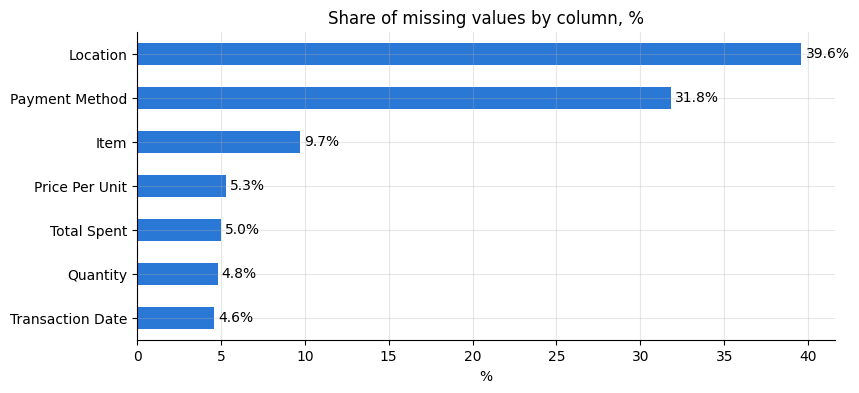

In [6]:
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

missing = df.isna().sum()
#display(missing)
missing_pct = (missing / len(df) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "pct": missing_pct})
display(missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False))

ax = missing_pct[missing_pct > 0].sort_values().plot(kind="barh", color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="{:.1f}%", padding=3)  # fmt="%.1f%%"
plt.title("Share of missing values by column, %")
plt.xlabel("%")
plt.show()

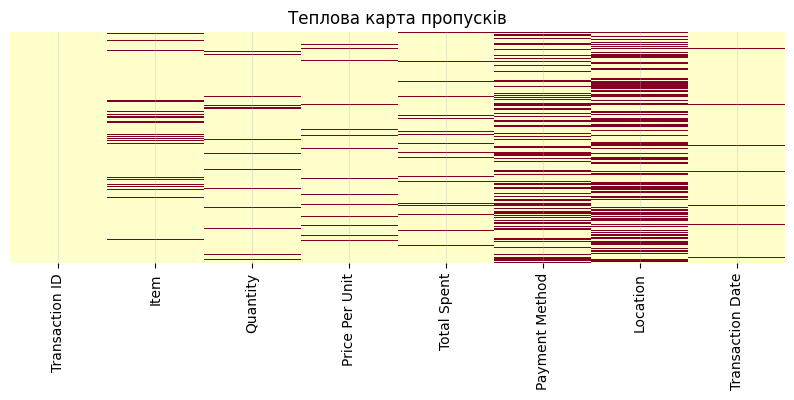

In [7]:
import seaborn as sns

# Графік 1: Heatmap пропусків
plt.figure(figsize=(10, 3))

sns.heatmap(
    df.isna(),         # True/False матриця
    cbar=False,          # без шкали кольорів
    cmap='YlOrRd',       # жовтий=є значення, червоний=NaN
    yticklabels=False,   # не показуємо номери рядків (їх занадто багато)
)
plt.title('Теплова карта пропусків')
plt.show()

✏️ **Спостереження:** у яких стовпцях пропусків найбільше? Як ви думаєте, які з них можна **відновити** за іншими стовпцями, а які ні?

- ...

---
# Частина 2. Очищення даних

Головне правило очищення: **спочатку відновлюємо те, що можна порахувати точно, і лише потім заповнюємо решту**. Кожне вигадане значення спотворює аналіз, тому вигадуємо якомога менше.

## Завдання 2.1. Назви стовпців

**Що зробити:** перейменуйте всі стовпці у формат `snake_case`: малі літери, слова через підкреслення. Наприклад, `Price Per Unit` → `price_per_unit`. Зробіть це **одним рядком** для всіх стовпців одразу і виведіть нові назви.

**Навіщо:** у назвах з пробілами й великими літерами легко помилитися, а до стовпців без пробілів можна звертатися ще й через крапку (`df.price_per_unit`).

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.columns.str.lower()` | усі назви малими літерами |
| `.str.replace(" ", "_")` | замінити пробіли на підкреслення |
| `df.columns = ...` | записати нові назви |

In [8]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
print(list(df.columns))

['transaction_id', 'item', 'quantity', 'price_per_unit', 'total_spent', 'payment_method', 'location', 'transaction_date']


## Завдання 2.2. Правильні типи даних

**Що зробити:**
1. Перетворіть `quantity`, `price_per_unit` і `total_spent` на числа, а `transaction_date` на дату. Використайте `errors="coerce"`.
2. Перевірте типи через `info()` і знову порахуйте пропуски в кожному стовпці.

**Навіщо:** відновлювати значення ми будемо за формулами (сума = кількість × ціна), а рахувати можна лише з числами. Тому типи виправляємо **до** заповнення пропусків.

**Перевірка:** кількість пропусків має збігтися з тим, що ви бачили в завданні 1.4. Якщо пропусків стало більше, отже, під час конвертації зникли значення, які не були ні `ERROR`, ні `UNKNOWN`. Поверніться до завдання 1.2 і подивіться, що це за значення.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `pd.to_numeric(df["col"], errors="coerce")` | текст → число |
| `pd.to_datetime(df["col"], errors="coerce")` | текст → дата |
| `for col in [...]:` | повторити ту саму дію для кількох стовпців |

In [9]:
for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

df.info()
display(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  object        
 1   item              9031 non-null   object        
 2   quantity          9521 non-null   float64       
 3   price_per_unit    9467 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   object        
 6   location          6039 non-null   object        
 7   transaction_date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 625.1+ KB


,0
transaction_id,0
item,969
quantity,479
price_per_unit,533
total_spent,502
payment_method,3178
location,3961
transaction_date,460


## Завдання 2.3. Відновлюємо числа точно

Між числовими стовпцями є жорсткий зв'язок: **сума = кількість × ціна**. А ще в меню кафе кожен товар має фіксовану ціну. Отже, багато пропусків можна не вгадувати, а **порахувати**.

**Що зробити:**
1. Перевірте, що кожен товар справді має **одну** ціну: порахуйте кількість різних цін для кожного товару.
2. Створіть словник `price_of_item` «товар → ціна».
3. Відновіть пропуски в такому порядку, щоразу виводячи, скільки рядків заповнено:
   - а) **ціна** за товаром, де товар відомий, а ціна ні;
   - б) **ціна** = сума / кількість, де ціна досі порожня, а сума й кількість відомі;
   - в) **кількість** = сума / ціна (округліть до цілого), де кількість порожня;
   - г) **сума** = кількість × ціна, де сума порожня.
4. Перевірте, що в усіх рядках, де заповнені всі три числа, кількість × ціна дорівнює сумі (порівнюйте значення, округлені до 2 знаків). Виведіть, скільки пропусків лишилося в трьох числових стовпцях.

**Навіщо:** це не здогадки, а математика, тож такі значення так само надійні, як оригінальні. Порядок важливий: спочатку ціна, бо без неї не порахувати ні кількість, ні суму.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.groupby("item")["price_per_unit"].nunique()` | скільки різних цін має кожен товар |
| `df.groupby("item")["price_per_unit"].median().to_dict()` | словник «товар → ціна» |
| `mask = df["a"].isna() & df["b"].notna()` | умова: `a` порожнє, а `b` заповнене |
| `df.loc[mask, "a"] = ...` | записати значення лише в рядки, що відповідають умові |
| `df.loc[mask, "item"].map(price_of_item)` | підставити значення зі словника |
| `.round()` | округлити до цілого |
| `df.dropna(subset=[...])` | лише рядки, де в цих стовпцях немає пропусків |

In [10]:
display(df.groupby("item")["price_per_unit"].nunique())
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print(price_of_item)

print()

# а) ціна за товаром
mask = df["price_per_unit"].isna() & df["item"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Price from item:", mask.sum())

print()

# б) ціна = сума / кількість
mask = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Price = total / quantity:", mask.sum())

print()

# в) кількість = сума / ціна
mask = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Quantity = total / price:", mask.sum())

print()

# г) сума = кількість × ціна
mask = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Total = quantity * price:", mask.sum())

print()

check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Mismatches:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())

,price_per_unit
item,
Cake,1
Coffee,1
Cookie,1
Juice,1
Salad,1
Sandwich,1
Smoothie,1
Tea,1


{'Cake': 3.0, 'Coffee': 2.0, 'Cookie': 1.0, 'Juice': 3.0, 'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Tea': 1.5}

Price from item: 479

Price = total / quantity: 48

Quantity = total / price: 456

Total = quantity * price: 479

Mismatches: 0


,0
quantity,23
price_per_unit,6
total_spent,23


## Завдання 2.4. Відновлюємо товар за ціною

Якщо товар невідомий, але відома ціна, можна спробувати визначити товар за ціною. Але це спрацює лише тоді, коли ціна належить **одному** товару.

**Що зробити:**
1. Серед рядків з відомим товаром подивіться, які товари продаються за кожною ціною.
2. Знайдіть ціни, за якими продається рівно **один** товар, і складіть словник `item_of_price` «ціна → товар» лише для таких цін.
3. Заповніть товар за цим словником там, де товар порожній, а ціна унікальна. Виведіть, скільки рядків заповнили і скільки рядків без товару лишилося. Подивіться, які ціни мають ці рядки.

**Навіщо:** якщо ціна належить кільком товарам, «зворотний» словник обере один з них для всіх рядків, і цей товар отримає чужі продажі. Тому однозначні випадки відновлюємо одразу, а неоднозначні розбираємо окремо в наступних завданнях.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.dropna(subset=["item"])` | лише рядки з відомим товаром |
| `.groupby("price_per_unit")["item"].unique()` | список товарів для кожної ціни |
| `.groupby("price_per_unit")["item"].nunique()` | кількість різних товарів для кожної ціни |
| `series[series == 1].index` | значення індексу, для яких виконується умова |
| `df["col"].isin(список)` | значення є в списку |
| `.groupby(...)["item"].first().to_dict()` | словник «ціна → перший товар з такою ціною» |

In [11]:
# Ваш код тут
known_items = df.dropna(subset=['item'])
known_items.groupby('price_per_unit')['item'].unique()

,item
price_per_unit,
1.0,[Cookie]
1.5,[Tea]
2.0,[Coffee]
3.0,"[Cake, Juice]"
4.0,"[Smoothie, Sandwich]"
5.0,[Salad]


In [12]:
n_items = known_items.groupby('price_per_unit')['item'].nunique()
unique_prices = n_items[n_items == 1].index
item_per_price = known_items[known_items['price_per_unit'].isin(unique_prices)].groupby('price_per_unit')['item'].first().to_dict()
item_per_price

{1.0: 'Cookie', 1.5: 'Tea', 2.0: 'Coffee', 5.0: 'Salad'}

In [13]:
mask = df['item'].isna() & df['price_per_unit'].isin(unique_prices)
df.loc[mask, 'item'] = df.loc[mask, 'price_per_unit'].map(item_per_price)

print(mask.sum())
print(df['item'].isna().sum())
df.loc[df['item'].isna(), 'price_per_unit'].value_counts(dropna=False)

489
480


,count
price_per_unit,
3.0,247
4.0,227
NaN,6


✏️ **Спостереження:** які ціни виявилися неоднозначними і яким товарам вони належать? Скільки рядків з такими цінами лишилися без товару?

- ...

## Завдання 2.5. Чи можна вгадати товар за іншими ознаками?

Для неоднозначної ціни треба обрати між двома товарами. Можливо, допоможуть інші стовпці: наприклад, торт частіше беруть у вихідні, а сік на виніс. **Перевірмо це на даних.**

**Що зробити:**
1. Створіть стовпець `is_weekend`: `True`, якщо продаж був у суботу або неділю.
2. Для пари **Cake** і **Juice** (серед рядків, де товар відомий) виведіть:
   - загальну частку кожного з двох товарів, %;
   - частку кожного товару окремо для `In-store` і `Takeaway`, %;
   - частку кожного товару окремо для буднів і вихідних, % (лише рядки з відомою датою).
3. Зробіть те саме для пари **Sandwich** і **Smoothie**.

**Навіщо:** якщо в якійсь ситуації один товар помітно переважає (скажімо, 70% на 30%), цю ознаку можна використати для заповнення. Якщо ж частки скрізь близькі до загальних, ознака нічого не підказує і використовувати її не можна. Аналітик спершу **перевіряє** припущення даними, а не заповнює пропуски «як здається логічним».

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["transaction_date"].dt.dayofweek >= 5` | `True` для суботи (5) і неділі (6) |
| `df["item"].value_counts(normalize=True) * 100` | частки значень у відсотках |
| `pd.crosstab(df["a"], df["item"], normalize="index") * 100` | частки товарів окремо для кожного значення `a`, % |

In [14]:
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5
df["is_weekend"].head()

,is_weekend
0,False
1,False
2,False
3,False
4,True


In [15]:
for pair_items in [['Cake', 'Juice'], ['Sandwich', 'Smoothie']]:
    pair = df[df['item'].isin(pair_items)]
    print("\n", "-" * 10, pair_items, "-" * 10)

    display((pair['item'].value_counts(normalize=True) * 100).round(1))
    print("-" * 10)

    display((pd.crosstab(pair["location"], pair["item"], normalize="index") * 100).round(1))
    print("-" * 10)

    pair_dated = pair[pair['transaction_date'].notna()]
    display((pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100).round(1))


 ---------- ['Cake', 'Juice'] ----------


,proportion
item,
Juice,50.7
Cake,49.3


----------


item,Cake,Juice
location,,
In-store,47.1,52.9
Takeaway,50.1,49.9


----------


item,Cake,Juice
is_weekend,,
False,49.5,50.5
True,47.8,52.2


... (2 outputs left out)

----------


item,Sandwich,Smoothie
location,,
In-store,53.5,46.5
Takeaway,53.2,46.8


----------


item,Sandwich,Smoothie
is_weekend,,
False,49.0,51.0
True,54.6,45.4


✏️ **Висновок:** чи відрізняються частки товарів залежно від локації або вихідних? Наскільки (у відсоткових пунктах)? Чи можна за цими ознаками надійно вгадати товар?
Чи відрізняються частки товарів залежно від локації або вихідних? Так, незначні відхилення є, але розподіл залишається близьким до рівномірного (близько 50/50).

Наскільки (у процентних пунктах)? Різниця між категоріями становить у середньому від 1 до 5 процентних пунктів (найбільше коливання — приблизно 5 п.п. для сендвічів і смузі у вихідні).

Чи можна за цими ознаками надійно вгадати товар? Ні, оскільки немає різкого перекосу в бік якогось одного товару за цими ознаками, надійно відновити пропущені назви з їхньою допомогою неможливо.



- ...

## Завдання 2.6. Заповнюємо неоднозначні товари

Є три способи заповнити товар для неоднозначної ціни:

| Спосіб | Що відбувається | Проблема |
|---|---|---|
| завжди частіший товар | усі рядки з ціною 3.0 → `Juice` | `Juice` отримує всі ці продажі, `Cake` жодного: рейтинг товарів спотворюється |
| випадково, **пропорційно часткам** | 49% рядків → `Cake`, 51% → `Juice` | товар у конкретному рядку вгадано навмання, але загальні пропорції правильні |
| `"Unknown"` | товар не вигадуємо | ці рядки випадають з аналізу товарів |

Використаємо **другий** спосіб, бо нам важливі загальні продажі товарів, а не кожен окремий рядок. Але позначимо такі рядки, щоб пізніше перевірити, чи вплинуло заповнення на висновки.

**Що зробити:**
1. Створіть стовпець `item_guessed` зі значенням `False` для всіх рядків.
2. Для ціни **3.0** (пара `["Cake", "Juice"]`) і ціни **4.0** (пара `["Sandwich", "Smoothie"]`):
   - порахуйте частки двох товарів серед рядків, де товар відомий;
   - заповніть порожній товар у рядках з цією ціною випадковим вибором з пари з такими частками;
   - позначте ці рядки в `item_guessed` як `True`.
3. Решту порожніх товарів (там, де не відома навіть ціна) заповніть `"Unknown"`. Виведіть кількість продажів кожного товару.

**Навіщо фіксувати випадковість:** без фіксованого «зерна» (`seed`) при кожному запуску рядки розподілятимуться інакше, і результати аналізу щоразу трохи змінюватимуться. Зерно `42` гарантує, що у вас і в одногрупників буде однаковий результат.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `rng = np.random.default_rng(42)` | генератор випадкових чисел із фіксованим зерном |
| `rng.choice(["A", "B"], size=n, p=[0.4, 0.6])` | `n` випадкових значень з A і B з імовірностями 40% і 60% |
| `.value_counts(normalize=True)[["A", "B"]]` | частки A і B саме в такому порядку |
| `shares.values` | частки як масив чисел для параметра `p` |
| `mask.sum()` | кількість рядків, що відповідають умові |
| `df["col"].fillna("Unknown")` | заповнити пропуски текстом |

In [16]:
rng = np.random.default_rng(42)
df['item_guessed'] = False

# Добавили запятую между ключами и значениями в словаре
pairs = {
    3.0: ['Cake', 'Juice'],
    4.0: ['Sandwich', 'Smoothie']
}

for price, items in pairs.items():
    # Исправили 'items' на 'item'
    shares = df[df["item"].isin(items)]["item"].value_counts(normalize=True)[items]
    display(shares)

    # Исправили 'items' на 'item'
    mask = df['item'].isna() & (df['price_per_unit'] == price)
    df.loc[mask, 'item'] = rng.choice(items, size=mask.sum(), p=shares.values)

    # Исправили 'df.lock' на 'df.loc' и 'items' на 'item'
    df.loc[mask, 'item_guessed'] = True

# Заполняем оставшиеся пропуски
df["item"] = df["item"].fillna("unknown")

# Выводим результат
display(df["item"].value_counts())

,proportion
item,
Cake,0.493074
Juice,0.506926


,proportion
item,
Sandwich,0.507858
Smoothie,0.492142


,count
item,
Juice,1295
Coffee,1291
Salad,1272
Cake,1262
Sandwich,1244
Cookie,1213
Smoothie,1210
Tea,1207
unknown,6


## Завдання 2.7. Спосіб оплати і локація

**Що зробити:**
1. Заповніть пропуски в `payment_method` і `location` значенням `"Unknown"`.
2. Перевірте, чи потрібна стандартизація тексту: для `item`, `payment_method` і `location` порівняйте кількість різних значень **до** і **після** прибирання пробілів і переведення в нижній регістр.

**Навіщо `"Unknown"`, а не найчастіше значення (мода):** у `payment_method` пропущено майже третину значень, а в `location` близько 40%. Якщо заповнити їх модою, один спосіб оплати отримає кілька тисяч чужих продажів і штучно «переможе» решту. `"Unknown"` чесно показує, що ми цього не знаємо.

**Навіщо перевірка тексту:** `"Cash"`, `"cash"` і `" Cash"` pandas вважає трьома різними значеннями. Якщо кількість різних значень після прибирання пробілів і регістру не змінилася, текст уже чистий і виправляти нічого не треба.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df["col"].fillna("Unknown")` | заповнити пропуски текстом |
| `df["col"].nunique()` | кількість різних значень |
| `df["col"].str.strip().str.lower()` | прибрати пробіли по краях і перевести в нижній регістр |

In [17]:
# Ваш код тут
df['payment_method'] = df['payment_method'].fillna("Unknown")
df['location'] = df['location'].fillna("Unknown")

df.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,is_weekend,item_guessed
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,False,False
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,False,False
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,False,False
3,TXN_7034554,Salad,2.0,5.0,10.0,Unknown,Unknown,2023-04-27,False,False
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,True,False


In [18]:
for col in ['item', 'payment_method', 'location']:
    print(col, df[col].nunique(), '-->', df[col].str.strip().str.lower().nunique())

item 9 --> 9
payment_method 4 --> 4
location 3 --> 3


## Завдання 2.8. Видаляємо те, що не відновити

**Що зробити:**
1. Видаліть рядки, де лишився пропуск у `transaction_date`, `quantity`, `price_per_unit` або `total_spent`.
2. Перетворіть `quantity` на цілі числа.
3. Виведіть: скільки рядків було в `df_original`, скільки стало, скільки відсотків втрачено, і скільки пропусків лишилося в усій таблиці (має бути 0).

**Навіщо:** дату неможливо відновити з інших стовпців, а продаж без дати не потрапить у жоден аналіз за часом. Числа ми вже відновили всюди, де це було можливо. Решта рядків без них не мають цінності для аналізу.

`quantity` переводимо в цілі числа лише тепер, бо в стовпці з пропусками цілий тип неможливий: pandas зберігає такі стовпці як дробові.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.dropna(subset=[...])` | видалити рядки з пропуском у вказаних стовпцях |
| `df["col"].astype(int)` | перетворити на цілі числа |
| `df.isna().sum().sum()` | загальна кількість пропусків у таблиці |

In [19]:
# Ваш код тут
before = len(df)
before


10000

In [20]:
df = df.dropna(subset=['transaction_date', 'quantity', 'price_per_unit', 'total_spent']).copy()
df['quantity'] = df['quantity'].astype(int)

print("Rows removed now:", before - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

Rows removed now: 486
Rows in original: 10000 | after cleaning: 9514
Loss, %: 4.9
Missing values left: 0


## Завдання 2.9. Нові ознаки з дати і збереження

**Що зробити:**
1. Додайте стовпці:
   - `month` — номер місяця (1–12);
   - `month_name` — назва місяця;
   - `weekday` — номер дня тижня (0 = понеділок);
   - `weekday_name` — назва дня тижня;
   - `is_weekend` — перерахуйте з `weekday`: `True` для суботи й неділі.
2. Покажіть перші рядки з датою і новими стовпцями.
3. Збережіть чисту таблицю у файл `FILE_OUT` без індексу.

**Навіщо:** групувати й будувати графіки за місяцями чи днями тижня зручніше з окремих стовпців, ніж щоразу витягати їх з дати. Номери потрібні для правильного порядку на графіках, а назви для підписів. Чистий файл стане в пригоді для подальшої роботи, наприклад у Tableau.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `.dt.month`, `.dt.month_name()` | номер і назва місяця |
| `.dt.dayofweek`, `.dt.day_name()` | номер і назва дня тижня |
| `df.to_csv(FILE_OUT, index=False)` | зберегти таблицю у файл |

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9514 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    9514 non-null   object        
 1   item              9514 non-null   object        
 2   quantity          9514 non-null   int64         
 3   price_per_unit    9514 non-null   float64       
 4   total_spent       9514 non-null   float64       
 5   payment_method    9514 non-null   object        
 6   location          9514 non-null   object        
 7   transaction_date  9514 non-null   datetime64[ns]
 8   is_weekend        9514 non-null   bool          
 9   item_guessed      9514 non-null   bool          
dtypes: bool(2), datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 687.5+ KB


In [22]:
df['month'] = df['transaction_date'].dt.month
df['month_name'] = df['transaction_date'].dt.month_name()
df['weekday'] = df['transaction_date'].dt.dayofweek
df['weekday_name'] = df['transaction_date'].dt.day_name()
df['is_weekend'] = df['weekday'] >= 5
print("Перші рядки з новими ознаками:")
print(df[['transaction_date', 'month', 'month_name', 'weekday', 'weekday_name', 'is_weekend']].head())

Перші рядки з новими ознаками:
  transaction_date  month month_name  weekday weekday_name  is_weekend
0       2023-09-08      9  September        4       Friday       False
1       2023-05-16      5        May        1      Tuesday       False
2       2023-07-19      7       July        2    Wednesday       False
3       2023-04-27      4      April        3     Thursday       False
4       2023-06-11      6       June        6       Sunday        True


In [23]:
df.to_csv(FILE_OUT, index=False)
print("Saved", FILE_OUT)

Saved cafe_sales_clean.csv


---
# Частина 3. Дослідницький аналіз (EDA)

Тепер дані чисті, і можна шукати відповіді на питання власника кафе. У кожному завданні спершу рахуйте числа, потім будуйте графік, а наприкінці формулюйте висновок.

💡 **Відсутність закономірності — теж висновок.** Якщо різниця між групами мізерна, так і напишіть. Це корисна інформація: на неї не варто спиратися в рішеннях.

## Завдання 3.1. Які товари продаються найкраще?

**Що зробити:**
1. Без рядків з товаром `"Unknown"` порахуйте для кожного товару кількість проданих одиниць і виторг.
2. Побудуйте два горизонтальні стовпчикові графіки поруч: одиниці й виторг, найбільше значення зверху, з підписами значень.
3. Порівняйте виторг товарів **з** рядками, де товар вгадано (`item_guessed`), і **без** них. Зберіть обидва результати в одну таблицю зі стовпцями `with_guessed` і `without_guessed`.

**Навіщо пункт 3:** у завданні 2.6 частину товарів ми вгадали. Якщо рейтинг товарів однаковий в обох варіантах, висновок надійний. Якщо змінюється, отже, висновок залежить від того, як ми заповнили пропуски, і про це треба попередити у звіті.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df.groupby("item")["col"].sum()` | сума для кожного товару |
| `fig, axes = plt.subplots(1, 2, figsize=(13, 4))` | два графіки поруч |
| `series.plot(kind="barh", ax=axes[0])` | малювати на першому графіку |
| `axes[0].bar_label(axes[0].containers[0])` | підписи значень |
| `~df["item_guessed"]` | рядки, де товар **не** вгадано |
| `pd.DataFrame({"a": series1, "b": series2})` | дві Series поруч в одній таблиці |

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9514 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    9514 non-null   object        
 1   item              9514 non-null   object        
 2   quantity          9514 non-null   int64         
 3   price_per_unit    9514 non-null   float64       
 4   total_spent       9514 non-null   float64       
 5   payment_method    9514 non-null   object        
 6   location          9514 non-null   object        
 7   transaction_date  9514 non-null   datetime64[ns]
 8   is_weekend        9514 non-null   bool          
 9   item_guessed      9514 non-null   bool          
 10  month             9514 non-null   int32         
 11  month_name        9514 non-null   object        
 12  weekday           9514 non-null   int32         
 13  weekday_name      9514 non-null   object        
dtypes: bool(2), datetime64[ns](1)

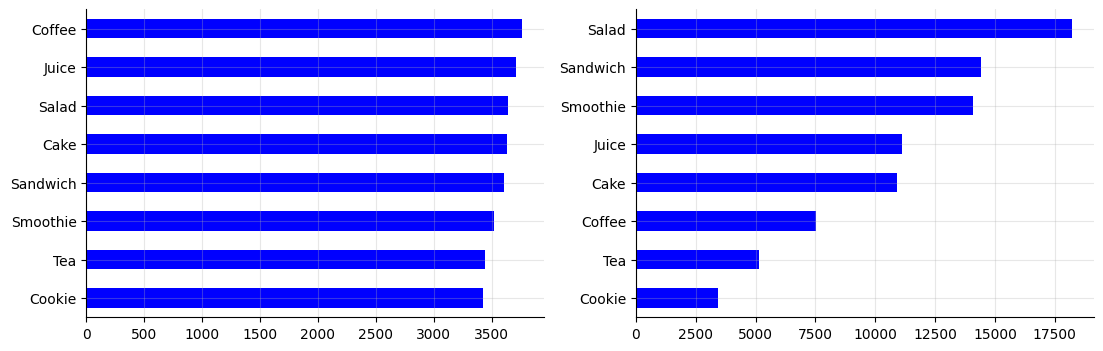

In [25]:
# Ваш код тут
known = df[df['item'] != 'Unknown']

units_by_item = known.groupby('item')['quantity'].sum().sort_values()
revenue_by_item = known.groupby('item')['total_spent'].sum().sort_values()  # ascending=False

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units_by_item.plot(kind='barh', ax=axes[0], color="blue")
axes[0].set_ylabel("")

revenue_by_item.plot(kind='barh', ax=axes[1], color="blue")
axes[1].set_ylabel("")

plt.show()

✏️ **Висновок:** які товари лідирують за кількістю, а які за виторгом? Чи збігаються ці рейтинги і чому? Чи змінився рейтинг без вгаданих рядків?

- ...

## Завдання 3.2. Спосіб оплати і локація

**Що зробити:**
1. Порахуйте виторг за кожним способом оплати і кожною локацією, а також частку кожного значення (включно з `"Unknown"`) у відсотках.
2. Побудуйте два горизонтальні стовпчикові графіки поруч: виторг за способами оплати і за локаціями, **без** `"Unknown"`.

**Навіщо прибирати `"Unknown"` з графіка:** якщо невідомих значень дуже багато, `"Unknown"` може стати найбільшим стовпчиком і створити хибне враження, що це «найпопулярніший спосіб оплати». Порівнювати між собою треба лише відомі значення. Але частку невідомих варто знати й чесно вказати у висновку.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `series / series.sum() * 100` | частки у відсотках |
| `series.drop("Unknown")` | прибрати значення з Series |
| `axes[0].bar_label(axes[0].containers[0], fmt="%.0f")` | підписи без знаків після коми |

In [26]:
without_guessed = df[(df['item'] != 'Unknown') & ~df['item_guessed']]

compare = pd.DataFrame({
    'with_guessed'    : known.groupby('item')['total_spent'].sum(),
    'without_guessed' : without_guessed.groupby('item')['total_spent'].sum()
}).sort_values('with_guessed', ascending=False)
compare

,with_guessed,without_guessed
item,,
Salad,18220.0,18220.0
Sandwich,14424.0,13068.0
Smoothie,14096.0,12776.0
Juice,11118.0,10023.0
Cake,10890.0,9834.0
Coffee,7532.0,7532.0
Tea,5161.5,5161.5
Cookie,3427.0,3427.0


✏️ **Висновок:**
- Яку частку виторгу становлять продажі з невідомим способом оплати й невідомою локацією?
- Серед відомих: який спосіб оплати приносить найбільше? Наскільки він відрізняється від інших?
- У закладі чи на виніс купують більше? Наскільки?

## Завдання 3.3. Продажі в часі

**Що зробити:**
1. **Виторг по місяцях:** стовпчиковий графік з назвами місяців на осі і червоною пунктирною лінією на рівні середнього місяця. Для назв використайте словник `{1: "Jan", 2: "Feb", ..., 12: "Dec"}`.
2. **Середній чек по днях тижня:** стовпчиковий графік, де вихідні виділено іншим кольором, з підписами значень (2 знаки після коми). Для назв днів використайте словник `{0: "Mon", 1: "Tue", ..., 6: "Sun"}`.
3. **Щоденний виторг:** лінійний графік, де денні значення показано блідою лінією, а поверх них ковзне середнє за 7 днів.

**Навіщо:** ці графіки відповідають на питання про сезонність і вихідні: коли кафе заробляє більше і чи варто, наприклад, посилювати персонал у певні дні.

⚠️ **Не обрізайте вісь Y.** Стовпчики завжди мають починатися з нуля. Якщо почати вісь, скажімо, з 6000, різниця в кілька відсотків виглядатиме як прірва.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `series.index = series.index.map(словник)` | замінити номери на назви |
| `plt.axhline(y, color="#e34948", linestyle="--")` | горизонтальна лінія-орієнтир |
| `color=["#e34948" if d in ["Sat", "Sun"] else "#2a78d6" for d in series.index]` | свій колір для вихідних |
| `series.rolling(7).mean()` | ковзне середнє за 7 значень |
| `alpha=0.3` | напівпрозора лінія |
| `plt.ylim(bottom=0)` | вісь Y від нуля |

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9514 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    9514 non-null   object        
 1   item              9514 non-null   object        
 2   quantity          9514 non-null   int64         
 3   price_per_unit    9514 non-null   float64       
 4   total_spent       9514 non-null   float64       
 5   payment_method    9514 non-null   object        
 6   location          9514 non-null   object        
 7   transaction_date  9514 non-null   datetime64[ns]
 8   is_weekend        9514 non-null   bool          
 9   item_guessed      9514 non-null   bool          
 10  month             9514 non-null   int32         
 11  month_name        9514 non-null   object        
 12  weekday           9514 non-null   int32         
 13  weekday_name      9514 non-null   object        
dtypes: bool(2), datetime64[ns](1)

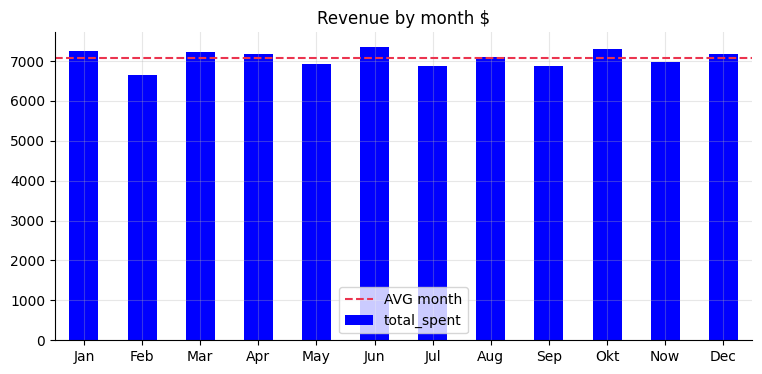

In [28]:
from matplotlib.typing import LineStyleType
month_name = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May",
               6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Okt", 11: "Now", 12: "Dec"
}

days = {
    0: "Mon", 1: "Tue",   2: "Wed", 3: "Thu", 4: "Fri",  5: "Sat", 6: "Sun",}
monthly =  df.groupby('month')['total_spent'].sum()
monthly.index = monthly.index.map(month_name)
monthly.plot(kind="bar", rot=0, color='blue')
plt.axhline(
    monthly.mean(), color="#eb344f", linestyle="--", label="AVG month"
)
plt.title("Revenue by month $")
plt.xlabel('')
plt.legend()
plt.show()

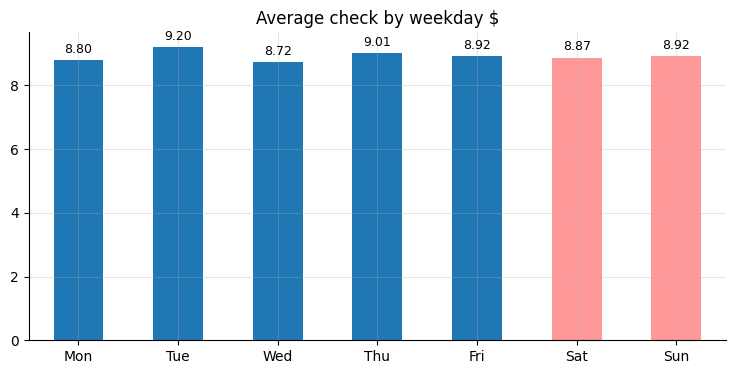

In [35]:


daily_avg = df.groupby('weekday')['total_spent'].mean()

days_dict = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
daily_avg.index = daily_avg.index.map(days_dict)

colors = ['#ff9999' if d in ['Sat', 'Sun'] else '#1f77b4' for d in daily_avg.index]

ax = daily_avg.plot(kind='bar', color=colors)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                textcoords='offset points')

plt.title('Average check by weekday $')
plt.xlabel('')
plt.ylim(bottom=0)
plt.xticks(rotation=0)
plt.show()

!!!

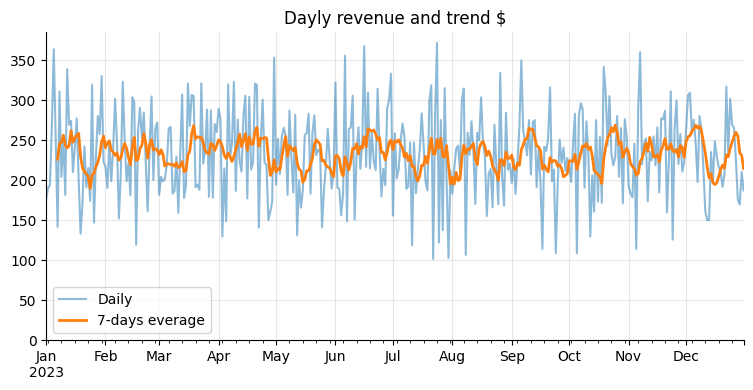

In [30]:
dayly = df.groupby('transaction_date')['total_spent'].sum()
dayly.plot(alpha = 0.5, label="Daily")
dayly.rolling(7).mean().plot(linewidth=2, label='7-days everage')
plt.title("Dayly revenue and trend $")
plt.xlabel('')
plt.ylim(bottom=0)
plt.legend()
plt.show()

✏️ **Висновок:**
- Який місяць найкращий і найслабший? На скільки відсотків вони відрізняються від середнього?
- Чи відрізняється середній чек у вихідні від буднів?
- Чи є сезонний тренд?

## Завдання 3.4. Викиди

**Що зробити:**
1. Побудуйте «ящики з вусами» (boxplot) для `quantity` і `total_spent` поруч.
2. Для `total_spent` порахуйте межі методом IQR:
   - `IQR = Q3 − Q1`, де Q1 і Q3 — 25-й і 75-й перцентилі;
   - нижня межа = `Q1 − 1.5 × IQR`, верхня межа = `Q3 + 1.5 × IQR`.
3. Порахуйте, скільки продажів виходять за ці межі, і подивіться, що це за продажі: який товар, кількість і ціна.
4. Вирішіть, що з ними робити: залишити, видалити чи обмежити.

**Навіщо:** викид — це не обов'язково помилка. Метод IQR лише позначає незвичні значення, а чи це помилка, вирішує аналітик, подивившись на них. Видаляти справжні великі покупки не можна: так ми занизимо виторг.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df[["a", "b"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))` | два boxplot поруч |
| `df["col"].quantile(0.25)` | 25-й перцентиль (Q1) |
| `(умова1) \| (умова2)` | «або» |
| `df.groupby([...])["col"].count()` | скільки рядків у кожній комбінації |

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9514 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    9514 non-null   object        
 1   item              9514 non-null   object        
 2   quantity          9514 non-null   int64         
 3   price_per_unit    9514 non-null   float64       
 4   total_spent       9514 non-null   float64       
 5   payment_method    9514 non-null   object        
 6   location          9514 non-null   object        
 7   transaction_date  9514 non-null   datetime64[ns]
 8   is_weekend        9514 non-null   bool          
 9   item_guessed      9514 non-null   bool          
 10  month             9514 non-null   int32         
 11  month_name        9514 non-null   object        
 12  weekday           9514 non-null   int32         
 13  weekday_name      9514 non-null   object        
dtypes: bool(2), datetime64[ns](1)

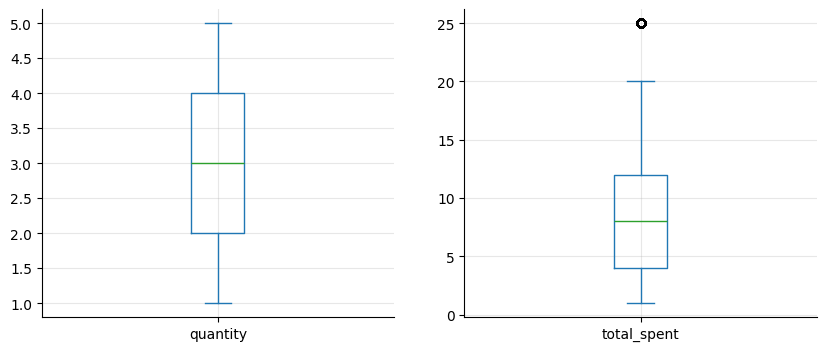

In [32]:
# Ваш код тут
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))

plt.show()


In [36]:
q1 = df['total_spent'].quantile(0.25)
q3 = df['total_spent'].quantile(0.75)
iqr = q3-q1
low= q1 - 1.5 * iqr
hight = q3 + 1.5 *iqr
outliers = df[(df['total_spent'] < low) | (df['total_spent'] > hight)]

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print(f"normal range: {low} - {hight}")
print("Outliers", len(outliers))

outliers.groupby(["item", "quantity", "price_per_unit"])["total_spent"].agg(
    ["count", "first"]
)

Q1: 4.0 Q3: 12.0 IQR: 8.0
normal range: -8.0 - 24.0
Outliers 259


,,,count,first
item,quantity,price_per_unit,,
Salad,5,5.0,259,25.0


✏️ **Рішення щодо викидів:** залишити / видалити / обмежити? Чому? Що це за покупки насправді?

- ...

## Завдання 3.5. Зв'язки між числами

**Що зробити:**
1. Порахуйте кореляції між `quantity`, `price_per_unit` і `total_spent`.
2. Покажіть таблицю кореляцій як теплову карту з шкалою від −1 до 1, з двома знаками після коми.
3. Заповніть таблицю інтерпретації нижче.

**Навіщо:** кореляція показує, чи рухаються два числа разом: від −1 (одне росте, інше падає) через 0 (зв'язку немає) до 1 (ростуть разом). Тут вона допоможе зрозуміти, що сильніше впливає на суму чека: кількість чи ціна.

**Команди, які знадобляться:**

| Команда | Що робить |
|---|---|
| `df[["a", "b", "c"]].corr()` | таблиця кореляцій |
| `table.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)` | теплова карта з фіксованою шкалою |
| `.format("{:.2f}")` | два знаки після коми |

In [ ]:
df_corr = df[["quantity", "price_per_unit", "total_spent"]].corr()
df_corr.style.background_gradient(
    cmap="coolwarm", vmin=-1, vmax=1
).format("{:.2f}")

✏️ **Інтерпретація:**

| Пара | Кореляція | Сила зв'язку | Пояснення |
|---|---|---|---|
| `quantity` ↔ `total_spent` | ... | ... | ... |
| `price_per_unit` ↔ `total_spent` | ... | ... | ... |
| `quantity` ↔ `price_per_unit` | ... | ... | ... |

---
# Частина 4. Звіт для власника кафе

**Що зробити:**
1. Порахуйте ключові показники і збережіть їх у змінні:
   - `total_revenue` — загальний виторг;
   - `n_transactions` — кількість продажів;
   - `average_check` — середній чек;
   - `top_item_original` — товар з найбільшим виторгом **без** вгаданих рядків;
   - `top_payment` — спосіб оплати з найбільшим виторгом серед відомих;
   - `location_share` — частки виторгу `In-store` і `Takeaway` серед відомих, %.
2. Виведіть їх як короткий звіт.
3. Напишіть висновки і рекомендації в клітинці нижче.

**Навіщо:** власнику кафе не потрібні графіки й код. Йому потрібні кілька чисел і чітка відповідь на питання «що робити далі». А ще він має знати обмеження даних: що частина значень невідома або відновлена.

In [ ]:
total_revenue = df["total_spent"].sum()
n_transactions = len(df)
average_check = df["total_spent"].mean()
top_item_original = without_guessed.groupby("item")["total_spent"].sum().idxmax()
top_payment = df[df["payment_method"] != "Unknown"].groupby("payment_method")["total_spent"].sum().idxmax()
known_location = df.groupby("location")["total_spent"].sum().drop("Unknown").sort_values(ascending=False)
location_share =  (known_location /  known_location.sum() * 100).round(1)


In [ ]:
# Ваш код тут3


print("CAFE SALES 2023: SUMMARY")
print("Total revenue, $:", round(total_revenue, 2))
print("Transactions:", n_transactions)
print("Average check, $:", round(average_check, 2))
print("Top item by revenue (original data):", top_item_original)
print("Top payment method (known only):", top_payment)
print("Revenue share by location, %:", location_share.to_dict())
print()
print("Revenue share by location, %:", pd.DataFrame(location_share))

✏️ **Висновки для власника кафе** (3–5 пунктів, кожен з числом):

1. ...
2. ...
3. ...

**Рекомендація** (мінімум одна):
- ...

**Обмеження даних** (що варто знати, читаючи цей звіт):
- ...

## ✅ Чеклист

**Частина 1**
- [ ] Завантажено дані, зроблено копію `df`
- [ ] Знайдено «сміттєві» значення в числових стовпцях і датах
- [ ] Перевірено дублікати
- [ ] `ERROR` і `UNKNOWN` замінено на пропуски, побудовано графік пропусків

**Частина 2**
- [ ] Назви стовпців у `snake_case`
- [ ] Числа й дата мають правильні типи, кількість пропусків перевірено
- [ ] Ціну, кількість і суму відновлено за формулами, розбіжностей 0
- [ ] Товар відновлено за унікальними цінами
- [ ] Перевірено, чи допомагають локація і вихідні вгадати товар
- [ ] Неоднозначні товари заповнено пропорційно, позначено `item_guessed`
- [ ] Оплату й локацію заповнено `"Unknown"`, текст перевірено
- [ ] Видалено невідновні рядки, пораховано втрати
- [ ] Додано ознаки з дати, збережено `FILE_OUT`

**Частина 3**
- [ ] 3.1 Товари: два графіки + порівняння з вгаданими і без
- [ ] 3.2 Оплата і локація без `"Unknown"` + частка невідомих
- [ ] 3.3 Місяці, дні тижня, щоденний тренд
- [ ] 3.4 Boxplot, межі IQR, рішення щодо викидів
- [ ] 3.5 Кореляції + інтерпретація

**Частина 4**
- [ ] Звіт з числами, рекомендація, обмеження даних

In [ ]:
# @title 💡 Розв'язки: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ========== ЧАСТИНА 1 ==========
# ---------- 1.1 ----------
df_original = pd.read_csv(FILE_IN)
df = df_original.copy()
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head(10))
df.info()

# ---------- 1.2 ----------
for col in ["Item", "Payment Method", "Location"]:
    display(df[col].value_counts(dropna=False))

for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    print(col, "->", df.loc[converted.isna() & df[col].notna(), col].unique())

converted = pd.to_datetime(df["Transaction Date"], errors="coerce")
print("Transaction Date ->", df.loc[converted.isna() & df["Transaction Date"].notna(), "Transaction Date"].unique())

display(df.isin(["ERROR", "UNKNOWN"]).sum())

# ---------- 1.3 ----------
print("Full duplicates:", df.duplicated().sum())
print("Repeated transaction IDs:", df["Transaction ID"].duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

# ---------- 1.4 ----------
df = df.replace(["ERROR", "UNKNOWN"], np.nan)

missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_report = pd.DataFrame({"missing": missing, "pct": missing_pct})
display(missing_report[missing_report["missing"] > 0].sort_values("pct", ascending=False))

ax = missing_pct[missing_pct > 0].sort_values().plot(kind="barh", color="#2a78d6")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Share of missing values by column, %")
plt.xlabel("%")
plt.show()

# ========== ЧАСТИНА 2 ==========
# ---------- 2.1 ----------
df.columns = df.columns.str.lower().str.replace(" ", "_")
print(list(df.columns))

# ---------- 2.2 ----------
for col in ["quantity", "price_per_unit", "total_spent"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")

df.info()
display(df.isna().sum())

# ---------- 2.3 ----------
display(df.groupby("item")["price_per_unit"].nunique())
price_of_item = df.groupby("item")["price_per_unit"].median().to_dict()
print(price_of_item)

# а) ціна за товаром
mask = df["price_per_unit"].isna() & df["item"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "item"].map(price_of_item)
print("Price from item:", mask.sum())

# б) ціна = сума / кількість
mask = df["price_per_unit"].isna() & df["total_spent"].notna() & df["quantity"].notna()
df.loc[mask, "price_per_unit"] = df.loc[mask, "total_spent"] / df.loc[mask, "quantity"]
print("Price = total / quantity:", mask.sum())

# в) кількість = сума / ціна
mask = df["quantity"].isna() & df["total_spent"].notna() & df["price_per_unit"].notna()
df.loc[mask, "quantity"] = (df.loc[mask, "total_spent"] / df.loc[mask, "price_per_unit"]).round()
print("Quantity = total / price:", mask.sum())

# г) сума = кількість × ціна
mask = df["total_spent"].isna() & df["quantity"].notna() & df["price_per_unit"].notna()
df.loc[mask, "total_spent"] = df.loc[mask, "quantity"] * df.loc[mask, "price_per_unit"]
print("Total = quantity * price:", mask.sum())

check = df.dropna(subset=["quantity", "price_per_unit", "total_spent"])
mismatch = (check["quantity"] * check["price_per_unit"]).round(2) != check["total_spent"].round(2)
print("Mismatches:", mismatch.sum())
display(df[["quantity", "price_per_unit", "total_spent"]].isna().sum())

# ---------- 2.4 ----------
known_items = df.dropna(subset=["item"])
display(known_items.groupby("price_per_unit")["item"].unique())

n_items = known_items.groupby("price_per_unit")["item"].nunique()
unique_prices = n_items[n_items == 1].index
item_of_price = known_items[known_items["price_per_unit"].isin(unique_prices)].groupby("price_per_unit")["item"].first().to_dict()
print(item_of_price)

mask = df["item"].isna() & df["price_per_unit"].isin(unique_prices)
df.loc[mask, "item"] = df.loc[mask, "price_per_unit"].map(item_of_price)
print("Item from unique price:", mask.sum())
print("Item still missing:", df["item"].isna().sum())
print(df.loc[df["item"].isna(), "price_per_unit"].value_counts(dropna=False))

# ---------- 2.5 ----------
df["is_weekend"] = df["transaction_date"].dt.dayofweek >= 5

for pair_items in [["Cake", "Juice"], ["Sandwich", "Smoothie"]]:
    pair = df[df["item"].isin(pair_items)]
    print(pair_items)
    display(pair["item"].value_counts(normalize=True) * 100)
    display(pd.crosstab(pair["location"], pair["item"], normalize="index") * 100)
    pair_dated = pair[pair["transaction_date"].notna()]
    display(pd.crosstab(pair_dated["is_weekend"], pair_dated["item"], normalize="index") * 100)
# Висновок: різниця між ситуаціями — 1–5 відсоткових пунктів, частки близькі до 50/50.
# Локація і вихідні майже не допомагають вгадати товар.

# ---------- 2.6 ----------
rng = np.random.default_rng(42)
df["item_guessed"] = False

pairs = {3.0: ["Cake", "Juice"], 4.0: ["Sandwich", "Smoothie"]}
for price, items in pairs.items():
    shares = df[df["item"].isin(items)]["item"].value_counts(normalize=True)[items]
    mask = df["item"].isna() & (df["price_per_unit"] == price)
    df.loc[mask, "item"] = rng.choice(items, size=mask.sum(), p=shares.values)
    df.loc[mask, "item_guessed"] = True
    print(price, items, shares.round(3).tolist(), "-> filled:", mask.sum())

df["item"] = df["item"].fillna("Unknown")
display(df["item"].value_counts())

# ---------- 2.7 ----------
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["location"] = df["location"].fillna("Unknown")

for col in ["item", "payment_method", "location"]:
    print(col, df[col].nunique(), "->", df[col].str.strip().str.lower().nunique())
# Кількість однакова: зайвих пробілів і різного регістру немає, стандартизація не потрібна.

# ---------- 2.8 ----------
before = len(df)
df = df.dropna(subset=["transaction_date", "quantity", "price_per_unit", "total_spent"])
df["quantity"] = df["quantity"].astype(int)

print("Rows removed now:", before - len(df))
print("Rows in original:", len(df_original), "| after cleaning:", len(df))
print("Loss, %:", round((len(df_original) - len(df)) / len(df_original) * 100, 1))
print("Missing values left:", df.isna().sum().sum())

# ---------- 2.9 ----------
df["month"] = df["transaction_date"].dt.month
df["month_name"] = df["transaction_date"].dt.month_name()
df["weekday"] = df["transaction_date"].dt.dayofweek
df["weekday_name"] = df["transaction_date"].dt.day_name()
df["is_weekend"] = df["weekday"] >= 5

display(df[["transaction_date", "month", "month_name", "weekday", "weekday_name", "is_weekend"]].head())
df.to_csv(FILE_OUT, index=False)
print("Saved:", FILE_OUT)

# ========== ЧАСТИНА 3 ==========
# ---------- 3.1 ----------
known = df[df["item"] != "Unknown"]
units_by_item = known.groupby("item")["quantity"].sum().sort_values()
revenue_by_item = known.groupby("item")["total_spent"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
units_by_item.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], padding=3)
axes[0].set_title("Units sold by item")
axes[0].set_ylabel("")
revenue_by_item.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by item, $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

without_guessed = df[(df["item"] != "Unknown") & ~df["item_guessed"]]
compare = pd.DataFrame({
    "with_guessed": known.groupby("item")["total_spent"].sum(),
    "without_guessed": without_guessed.groupby("item")["total_spent"].sum(),
}).sort_values("with_guessed", ascending=False)
display(compare)

# ---------- 3.2 ----------
revenue_by_payment = df.groupby("payment_method")["total_spent"].sum()
revenue_by_location = df.groupby("location")["total_spent"].sum()
display((revenue_by_payment / revenue_by_payment.sum() * 100).round(1))
display((revenue_by_location / revenue_by_location.sum() * 100).round(1))

known_payment = revenue_by_payment.drop("Unknown").sort_values()
known_location = revenue_by_location.drop("Unknown").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
known_payment.plot(kind="barh", ax=axes[0], color="#2a78d6")
axes[0].bar_label(axes[0].containers[0], fmt="%.0f", padding=3)
axes[0].set_title("Revenue by payment method (known only), $")
axes[0].set_ylabel("")
known_location.plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].bar_label(axes[1].containers[0], fmt="%.0f", padding=3)
axes[1].set_title("Revenue by location (known only), $")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

# ---------- 3.3 ----------
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
               7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
weekday_names = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}

monthly = df.groupby("month")["total_spent"].sum()
monthly.index = monthly.index.map(month_names)
monthly.plot(kind="bar", rot=0, color="#2a78d6")
plt.axhline(monthly.mean(), color="#e34948", linestyle="--", label="Average month")
plt.title("Revenue by month, $")
plt.xlabel("")
plt.legend()
plt.show()

avg_check = df.groupby("weekday")["total_spent"].mean()
avg_check.index = avg_check.index.map(weekday_names)
colors = ["#e34948" if d in ["Sat", "Sun"] else "#2a78d6" for d in avg_check.index]
ax = avg_check.plot(kind="bar", rot=0, color=colors)
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.title("Average check by day of week, $")
plt.xlabel("")
plt.show()

daily = df.groupby("transaction_date")["total_spent"].sum()
daily.plot(alpha=0.3, label="Daily")
daily.rolling(7).mean().plot(linewidth=2, label="7-day average")
plt.title("Daily revenue and trend, $")
plt.xlabel("")
plt.ylim(bottom=0)
plt.legend()
plt.show()

# ---------- 3.4 ----------
df[["quantity", "total_spent"]].plot(kind="box", subplots=True, layout=(1, 2), figsize=(10, 4))
plt.show()

q1 = df["total_spent"].quantile(0.25)
q3 = df["total_spent"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
outliers = df[(df["total_spent"] < low) | (df["total_spent"] > high)]
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Normal range:", low, "-", high)
print("Outliers:", len(outliers))
display(outliers.groupby(["item", "quantity", "price_per_unit"])["total_spent"].agg(["count", "first"]))
# Усі «викиди» — це 5 салатів по $5 = $25. Це звичайна покупка, а не помилка: залишаємо.

# ---------- 3.5 ----------
corr = df[["quantity", "price_per_unit", "total_spent"]].corr()
display(corr.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))

# ========== ЧАСТИНА 4 ==========
total_revenue = df["total_spent"].sum()
n_transactions = len(df)
average_check = df["total_spent"].mean()
top_item_original = without_guessed.groupby("item")["total_spent"].sum().idxmax()
top_payment = df[df["payment_method"] != "Unknown"].groupby("payment_method")["total_spent"].sum().idxmax()
location_share = (known_location / known_location.sum() * 100).round(1)

print("CAFE SALES 2023: SUMMARY")
print("Total revenue, $:", round(total_revenue, 2))
print("Transactions:", n_transactions)
print("Average check, $:", round(average_check, 2))
print("Top item by revenue (original data):", top_item_original)
print("Top payment method (known only):", top_payment)
print("Revenue share by location, %:", location_share.to_dict())